In [252]:
import numpy as np
import matplotlib.pyplot as plt

# Import bf image

In [253]:
bf_matrix = np.genfromtxt('./data/csv/bf_matrix.csv', delimiter=',').reshape(1600,128)

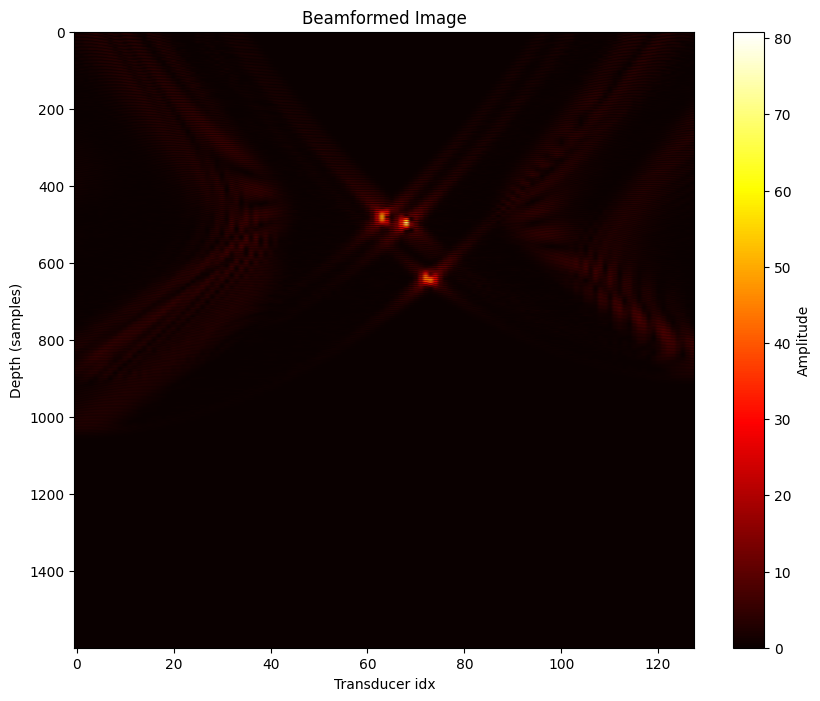

In [254]:
plt.figure(figsize=(10, 8))
plt.imshow(np.abs(bf_matrix), cmap='hot', aspect='auto')
plt.title("Beamformed Image")
plt.xlabel("Transducer idx")
plt.ylabel("Depth (samples)")
plt.colorbar(label="Amplitude")
plt.savefig("./data/images/bf_image.png")
plt.show()

# Rescale image

C:\Users\Acer\AppData\Local\Temp\ipykernel_7772\2316973036.py:7: RuntimeWarning: divide by zero encountered in log10
  im1 = ax[1].imshow(np.log10(bf_matrix), cmap='hot', aspect='auto')
C:\Users\Acer\AppData\Local\Temp\ipykernel_7772\2316973036.py:7: RuntimeWarning: invalid value encountered in log10
  im1 = ax[1].imshow(np.log10(bf_matrix), cmap='hot', aspect='auto')


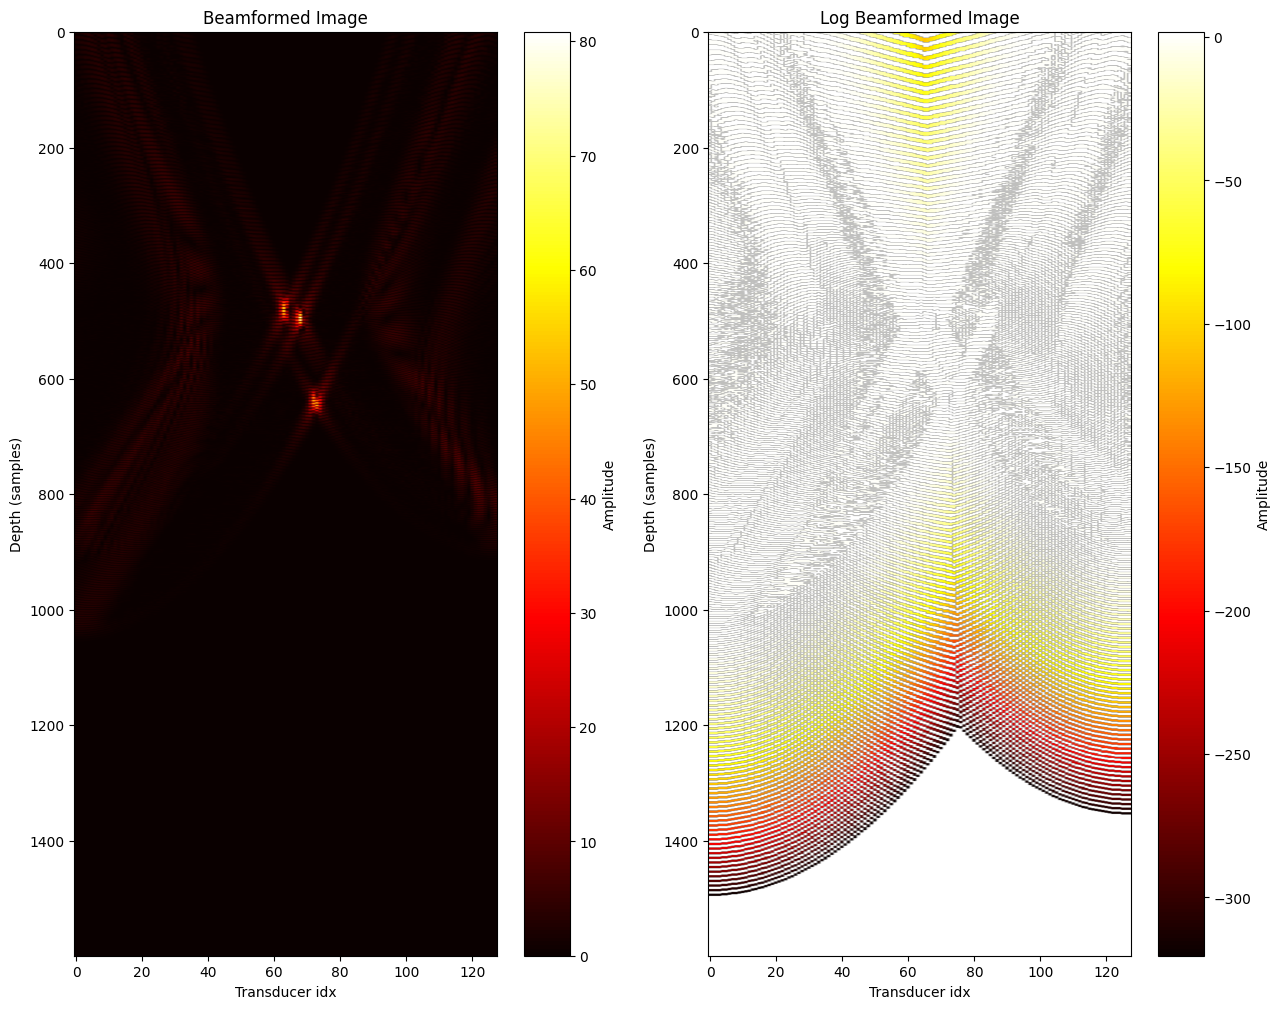

In [255]:
fig, ax = plt.subplots(1,2, figsize=(15, 12))
im0 = ax[0].imshow(np.abs(bf_matrix), cmap='hot', aspect='auto')
ax[0].set_title("Beamformed Image")
ax[0].set_xlabel("Transducer idx")
ax[0].set_ylabel("Depth (samples)")
fig.colorbar(im0, label="Amplitude", ax=ax[0])
im1 = ax[1].imshow(np.log10(bf_matrix), cmap='hot', aspect='auto')
ax[1].set_title("Log Beamformed Image") 
ax[1].set_xlabel("Transducer idx")
ax[1].set_ylabel("Depth (samples)")
fig.colorbar(im1, label="Amplitude", ax=ax[1])
plt.show()

In [256]:
#return the maximum value of the beamformed image
max_val = np.max(np.abs(bf_matrix))
print("Maximum value of the beamformed image: ", max_val)

Maximum value of the beamformed image:  80.83783393350735


# Get image zone

In [257]:
def extract_highest_value_region(bf_matrix, submatrix_size=100):
    row, col = np.unravel_index(np.argmax(np.abs(bf_matrix)), bf_matrix.shape)
    
    half_size = int(submatrix_size/2)
    row_start = row - half_size
    row_end = row + half_size
    col_start = col - half_size
    col_end = col + half_size

    return bf_matrix[row_start:row_end, col_start:col_end]

In [258]:
high_energy_zone = extract_highest_value_region(bf_matrix, submatrix_size=120)
print("High energy zone shape: ", high_energy_zone.shape)

High energy zone shape:  (120, 120)


# Visualize lobes

In [259]:
selected_res_zone = bf_matrix

In [260]:
max_val_row, max_val_col = np.unravel_index(np.argmax(np.abs(selected_res_zone)), selected_res_zone.shape)

C:\Users\Acer\AppData\Local\Temp\ipykernel_7772\1806711419.py:5: RuntimeWarning: divide by zero encountered in log10
  im1 = ax[1].imshow(np.log10(np.abs(selected_res_zone)), cmap='hot', aspect='auto')


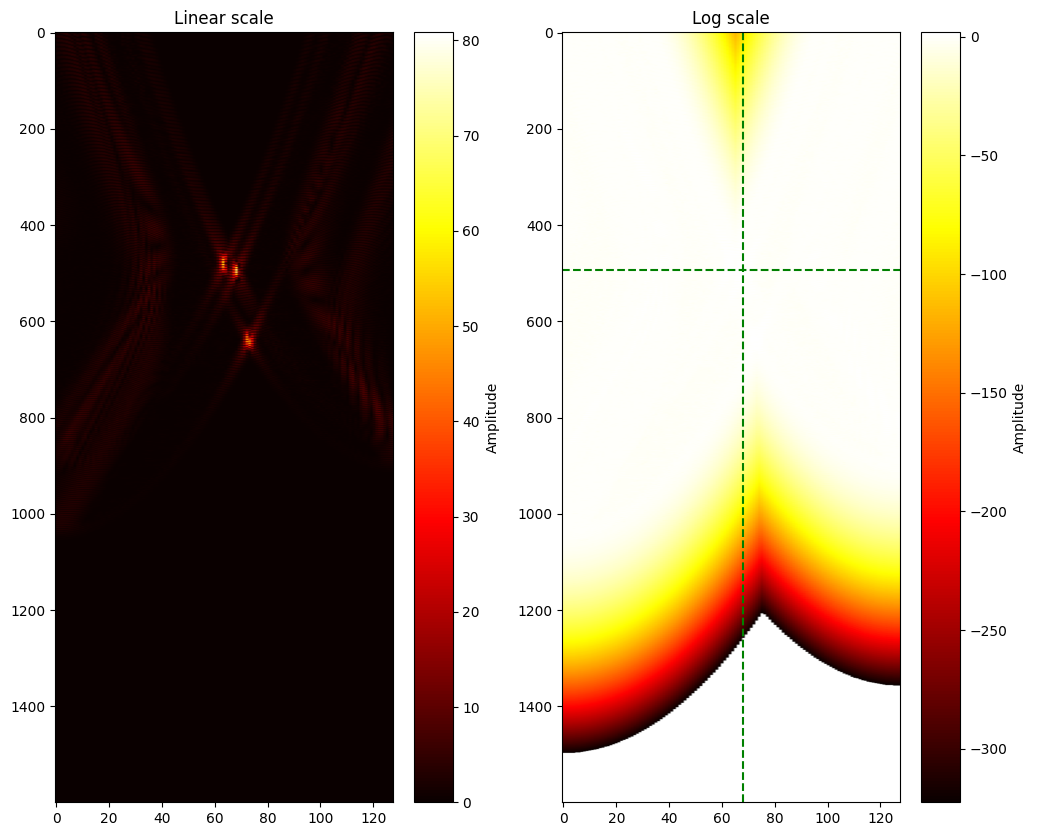

In [261]:
fig, ax = plt.subplots(1,2, figsize=(12, 10))
im0 = ax[0].imshow(np.abs(selected_res_zone), cmap='hot', aspect='auto')
ax[0].set_title("Linear scale")
plt.colorbar(im0, label="Amplitude", ax=ax[0])
im1 = ax[1].imshow(np.log10(np.abs(selected_res_zone)), cmap='hot', aspect='auto')
ax[1].set_title("Log scale")
ax[1].axhline(y=max_val_row, color='g', linestyle='--')
ax[1].axvline(x=max_val_col, color='g', linestyle='--')
plt.colorbar(im1, label="Amplitude", ax=ax[1])
plt.show()

# Metrics

In [262]:
def calculate_resolution(function):
    half_max = max(function)/2
    left_idx = np.where(function >= half_max)[0][0] #first point where the profile is greater than half max
    right_idx = np.where(function >= half_max)[0][-1] #last point where the profile is greater than half max
    return left_idx, right_idx, right_idx - left_idx

## Lateral res (horizontal)

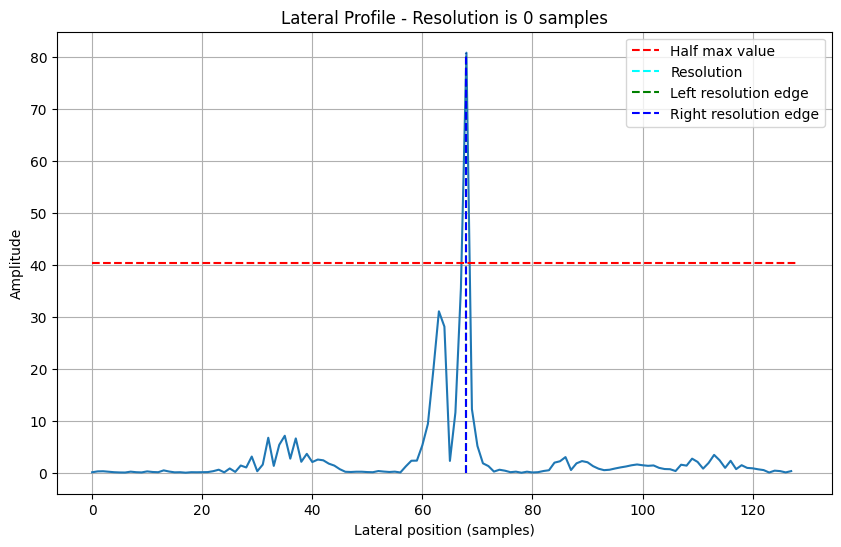

In [270]:
lateral_profile = np.abs(selected_res_zone[max_val_row, :]) #we take values along the row with maximum value

lat_left_idx, lat_right_idx, lat_res = calculate_resolution(lateral_profile)

plt.figure(figsize=(10, 6))
plt.plot(lateral_profile)
plt.title(f"Lateral Profile - Resolution is {lat_res} samples")
plt.xlabel("Lateral position (samples)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.hlines(max(lateral_profile)/2, 0, lateral_profile.shape[0], colors='r', linestyles='--', label='Half max value')
plt.hlines(max(lateral_profile)/2, lat_left_idx, lat_right_idx, colors='cyan', linestyles='--', label='Resolution')
plt.vlines(lat_left_idx, 0, max(lateral_profile), colors='g', linestyles='--', label='Left resolution edge')
plt.vlines(lat_right_idx, 0, max(lateral_profile), colors='b', linestyles='--', label='Right resolution edge')
plt.legend()
plt.show()



## Axial resolution (vertical)

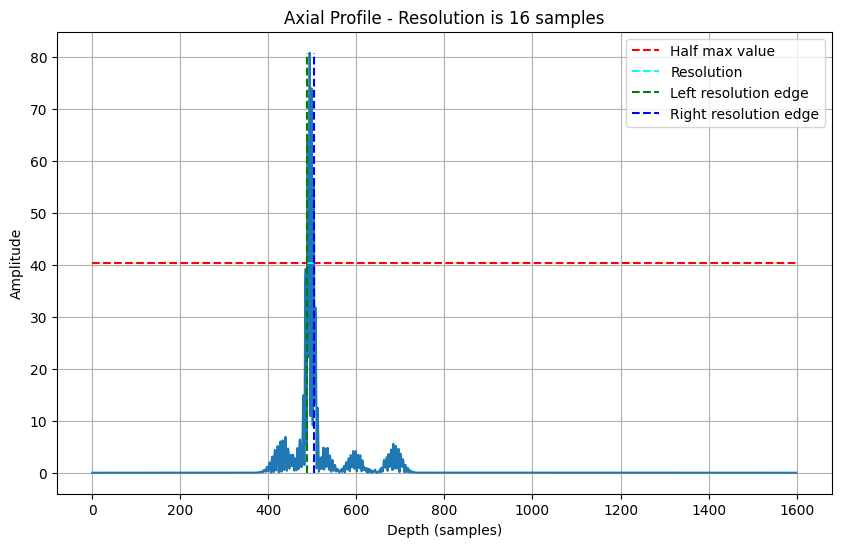

In [269]:
axial_profile = np.abs(selected_res_zone[:, max_val_col]) #we take values along the column with maximum value

ax_left_idx, ax_right_idx, ax_res = calculate_resolution(axial_profile)

plt.figure(figsize=(10, 6))
plt.plot(axial_profile)
plt.title(f"Axial Profile - Resolution is {ax_res} samples")
plt.xlabel("Depth (samples)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.hlines(max(axial_profile)/2, 0, axial_profile.shape[0], colors='r', linestyles='--', label='Half max value')
plt.hlines(max(axial_profile)/2, ax_left_idx, ax_right_idx, colors='cyan', linestyles='--', label='Resolution')
plt.vlines(ax_left_idx, 0, max(axial_profile), colors='g', linestyles='--', label='Left resolution edge')
plt.vlines(ax_right_idx, 0, max(axial_profile), colors='b', linestyles='--', label='Right resolution edge')
plt.legend()
plt.show()